# Análise de Dados de Internamentos Hospitalares
Este notebook executa a análise exploratória e estatística carregando os dados diretamente a partir de um ficheiro CSV externo.

## 1. Importação de Bibliotecas e Leitura do Ficheiro CSV

In [15]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
# Visual style configuration for plots
sns.set_theme(style="whitegrid")

# Define file path by navigating 3 levels up from the current working directory
file_path = (Path.cwd() / "../../../tools/data-generation/output/dataset.csv").resolve()

# Check if the file exists before reading
if file_path.exists():
    df = pd.read_csv(file_path)
    print(f"File successfully loaded from: {file_path}\n")
else:
    print(f"Error: File not found at path:\n{file_path}")
    df = None

File successfully loaded from: C:\Users\RuiMiguelSoaresRodri\Desktop\Mestrado\2_Ano\PI\PatientFlow\tools\data-generation\output\dataset.csv



## 2. Processamento e Cálculo de Métricas (Idade e Tempo de Internamento)

In [16]:
if df is not None:
    # Converter colunas de data/hora para o formato datetime
    df['birthdate'] = pd.to_datetime(df['birthdate'])
    df['admission date'] = pd.to_datetime(df['admission date'])
    df['discharge date'] = pd.to_datetime(df['discharge date'])

    # 1. Renomear 'diagnosis code' para 'diagnosis_code'
    df = df.rename(columns={'diagnosis code': 'diagnosis_code'})

    # 2. Calcular a idade na data de admissão (em anos)
    df['age'] = ((df['admission date'] - df['birthdate']).dt.days / 365.25).astype(int)

    # 3. Calcular o Tempo de Internamento (LOS) em dias completos
    df['los_days'] = (df['discharge date'] - df['admission date']).dt.days

    # 4. Extrair o mês e o dia da semana da data de admissão
    df['month'] = df['admission date'].dt.month
    df['admission_weekday'] = df['admission date'].dt.day_name()  # Ex: 'Monday', 'Tuesday'... (ou use .dt.weekday para números 0-6)

    # 5. Determinar a altura do dia (Manhã, Tarde, Noite, Madrugada)
    def get_period_of_day(hour):
        if 6 <= hour < 12:
            return 'Morning'
        elif 12 <= hour < 18:
            return 'Afternoon'
        elif 18 <= hour < 24:
            return 'Evening'
        else:
            return 'Night'

    df['time_period'] = df['admission date'].dt.hour.apply(get_period_of_day)

    # 6. Determinar a estação do ano na data de admissão
    def get_season(date):
        month = date.month
        day = date.day
        if (month == 12 and day >= 21) or month in [1, 2] or (month == 3 and day < 20):
            return 'Winter'
        elif (month == 3 and day >= 20) or month in [4, 5] or (month == 6 and day < 21):
            return 'Spring'
        elif (month == 6 and day >= 21) or month in [7, 8] or (month == 9 and day < 23):
            return 'Summer'
        else:
            return 'Autumn'

    df['season'] = df['admission date'].apply(get_season)

    # 7. Manter as colunas pretendidas (incluindo as novas extrações)
    columns_to_keep = [
        'gender', 'diagnosis_code', 'age', 'los_days', 
        'month', 'admission_weekday', 'time_period', 'season'
    ]
    df = df[columns_to_keep]

    # Visualizar as primeiras linhas
    display(df.head())

,gender,diagnosis_code,age,los_days,month,admission_weekday,time_period,season
0,F,K56.60,73,5,9,Thursday,Morning,Autumn
1,F,R65.21,40,8,9,Thursday,Morning,Autumn
2,F,K80.20,78,2,9,Friday,Morning,Autumn
3,F,K56.60,77,5,9,Friday,Morning,Autumn
4,M,J96.00,71,14,9,Friday,Afternoon,Autumn


## 3. Resumo Estatístico dos Dados

In [17]:
if df is not None:
    print("=== GENERAL STATISTICS ===")
    print(f"Total patients: {len(df)}")
    print(f"Average age: {df['age'].mean():.1f} years")
    print(f"Average length of stay: {df['los_days'].mean():.2f} days")

    print("\n=== GENDER DISTRIBUTION ===")
    print(df['gender'].value_counts())

    print("\n=== COUNT BY ICD-10 DIAGNOSIS CODE ===")
    print(df['diagnosis_code'].value_counts())
    
    print("\n=== ADMISSIONS BY SEASON ===")
    print(df['season'].value_counts())

=== GENERAL STATISTICS ===
Total patients: 27286
Average age: 70.4 years
Average length of stay: 7.91 days

=== GENDER DISTRIBUTION ===
gender
M    13737
F    13549
Name: count, dtype: int64

=== COUNT BY ICD-10 DIAGNOSIS CODE ===
diagnosis_code
C18.9     2216
K35.80    2203
K80.20    2195
K56.60    2193
K40.90    2175
J18.9     1950
D64.9     1942
N17.9     1933
E86.0     1894
I50.9     1873
N39.0     1868
A41.9     1240
J96.00    1215
I46.9     1196
R65.21    1193
Name: count, dtype: int64

=== ADMISSIONS BY SEASON ===
season
Spring    7601
Winter    7264
Autumn    7130
Summer    5291
Name: count, dtype: int64


## 4. Visualização Gráfica

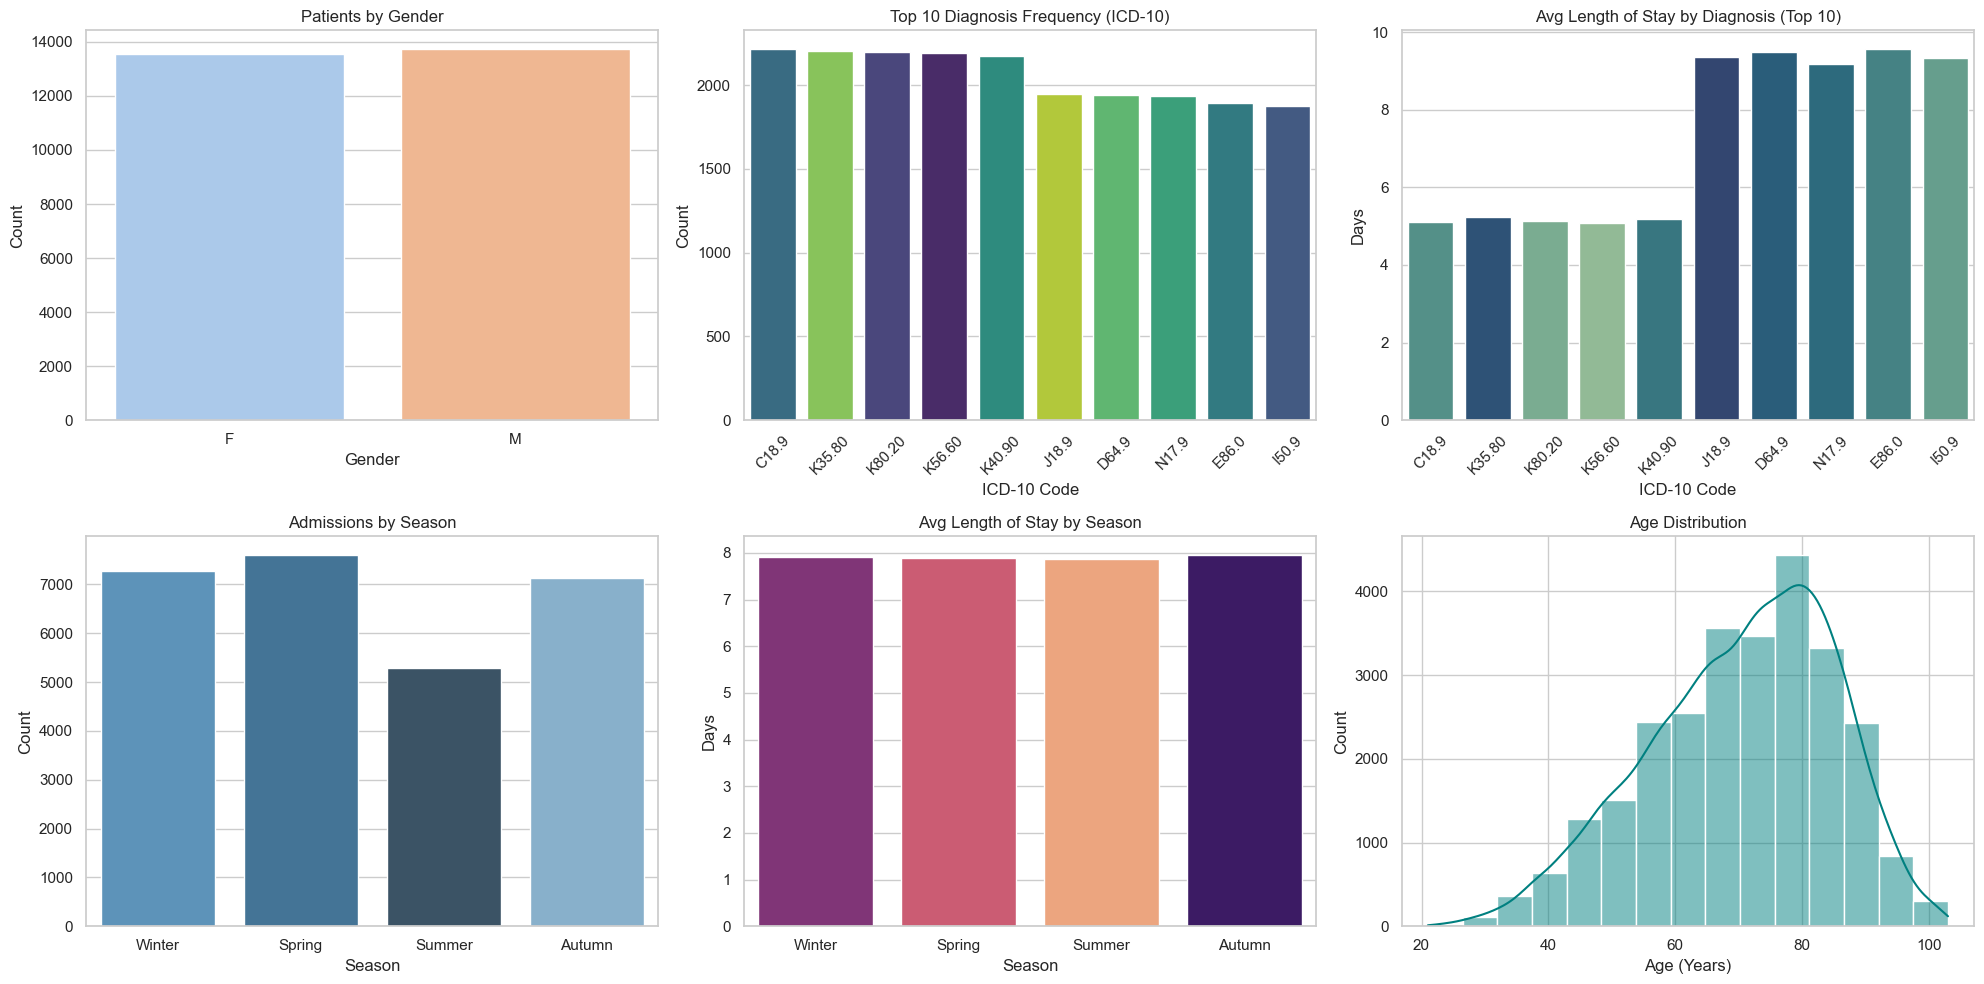

In [18]:
if df is not None:
    fig, axes = plt.subplots(2, 3, figsize=(20, 10))

    # Definir o Top 10 diagnósticos mais frequentes
    top_10_diag = df['diagnosis_code'].value_counts().head(10).index
    df_top10 = df[df['diagnosis_code'].isin(top_10_diag)]

    # 1. Gender Distribution (Linha 0, Coluna 0)
    sns.countplot(data=df, x='gender', hue='gender', palette='pastel', legend=False, ax=axes[0, 0])
    axes[0, 0].set_title('Patients by Gender')
    axes[0, 0].set_xlabel('Gender')
    axes[0, 0].set_ylabel('Count')

    # 2. Top 10 Diagnosis Frequency (Linha 0, Coluna 1)
    sns.countplot(
        data=df_top10, 
        x='diagnosis_code', 
        hue='diagnosis_code',
        palette='viridis', 
        order=top_10_diag, 
        legend=False,
        ax=axes[0, 1]
    )
    axes[0, 1].set_title('Top 10 Diagnosis Frequency (ICD-10)')
    axes[0, 1].set_xlabel('ICD-10 Code')
    axes[0, 1].set_ylabel('Count')
    axes[0, 1].tick_params(axis='x', rotation=45)

    # 3. Average Length of Stay by Diagnosis Code (Linha 0, Coluna 2)
    sns.barplot(
        data=df_top10, 
        x='diagnosis_code', 
        y='los_days', 
        hue='diagnosis_code',
        palette='crest', 
        order=top_10_diag,
        errorbar=None, 
        legend=False,
        ax=axes[0, 2]
    )
    axes[0, 2].set_title('Avg Length of Stay by Diagnosis (Top 10)')
    axes[0, 2].set_xlabel('ICD-10 Code')
    axes[0, 2].set_ylabel('Days')
    axes[0, 2].tick_params(axis='x', rotation=45)

    # 4. Admissions by Season (Linha 1, Coluna 0)
    sns.countplot(
        data=df, 
        x='season', 
        hue='season', 
        palette='Blues_d', 
        order=['Winter', 'Spring', 'Summer', 'Autumn'],
        legend=False, 
        ax=axes[1, 0]
    )
    axes[1, 0].set_title('Admissions by Season')
    axes[1, 0].set_xlabel('Season')
    axes[1, 0].set_ylabel('Count')

    # 5. Average Length of Stay by Season (Linha 1, Coluna 1)
    sns.barplot(
        data=df, 
        x='season', 
        y='los_days', 
        hue='season', 
        palette='magma', 
        order=['Winter', 'Spring', 'Summer', 'Autumn'],
        errorbar=None, 
        legend=False, 
        ax=axes[1, 1]
    )
    axes[1, 1].set_title('Avg Length of Stay by Season')
    axes[1, 1].set_xlabel('Season')
    axes[1, 1].set_ylabel('Days')

    # 6. Age Distribution (Linha 1, Coluna 2)
    sns.histplot(data=df, x='age', kde=True, color='teal', bins=15, ax=axes[1, 2])
    axes[1, 2].set_title('Age Distribution')
    axes[1, 2].set_xlabel('Age (Years)')
    axes[1, 2].set_ylabel('Count')

    plt.tight_layout()
    plt.show()

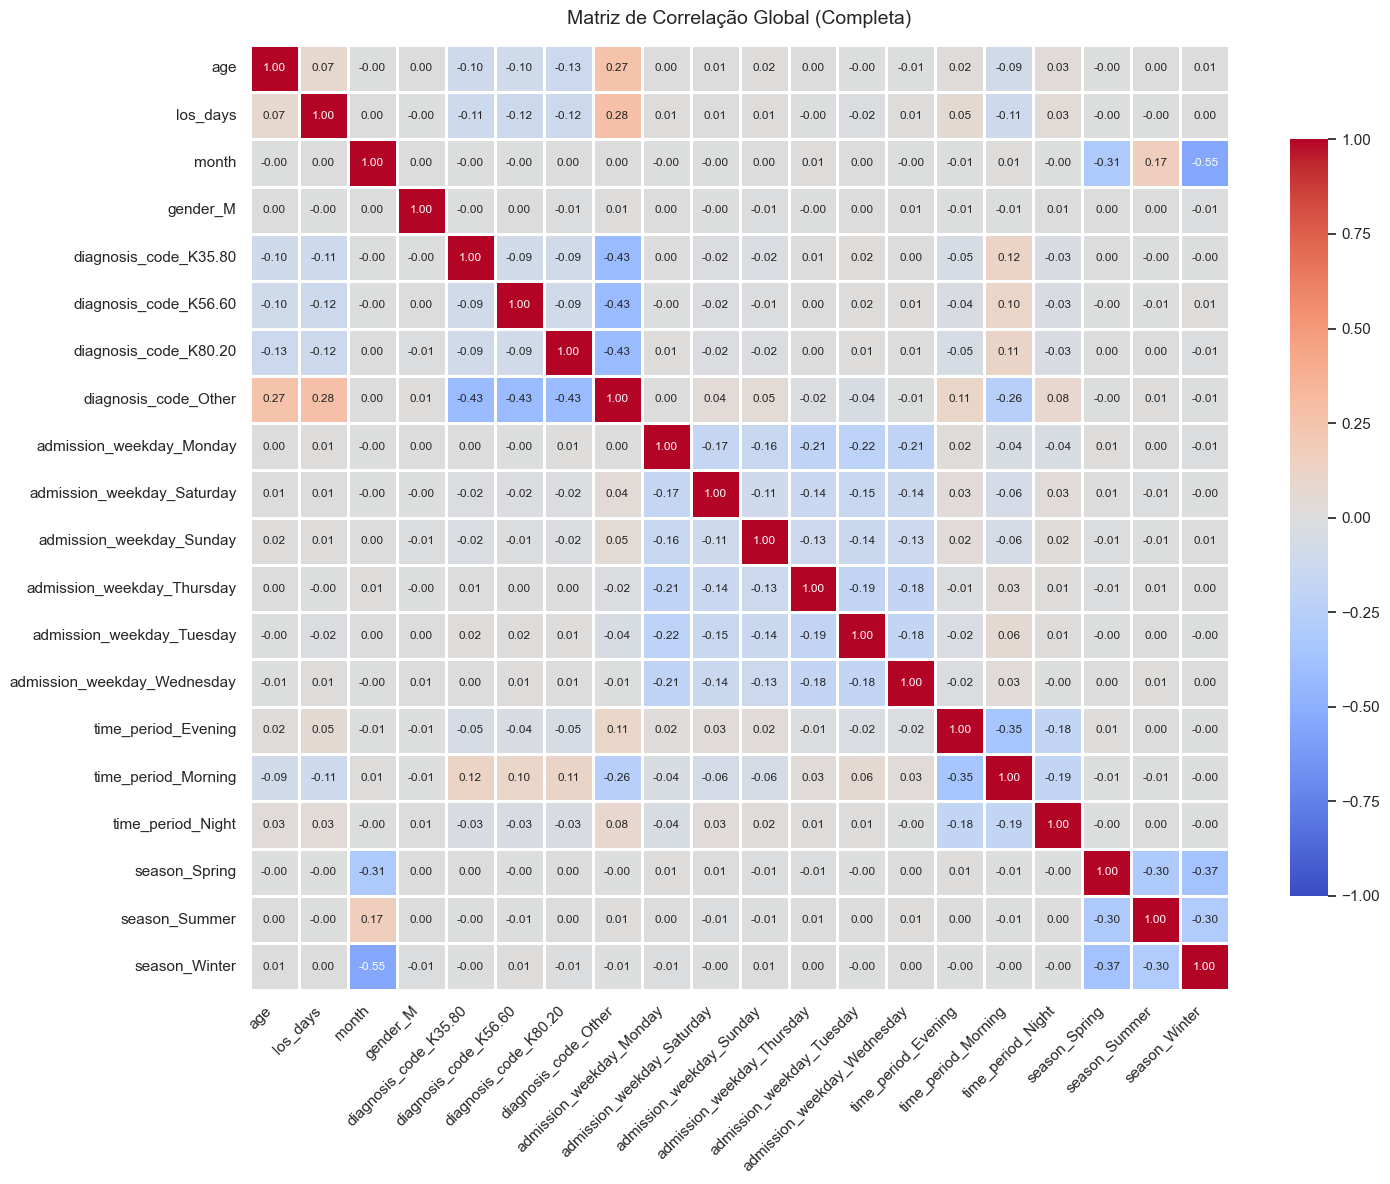

In [19]:
if df is not None:
    # 1. Manter os 4 diagnósticos mais frequentes e agrupar os restantes em 'Other'
    df_clean = df.copy()
    top_4_diag = df_clean['diagnosis_code'].value_counts().head(4).index
    df_clean['diagnosis_code'] = df_clean['diagnosis_code'].apply(
        lambda x: x if x in top_4_diag else 'Other'
    )

    # 2. Converter variáveis categóricas em One-Hot Encoding (dummy variables)
    df_encoded = pd.get_dummies(df_clean, drop_first=True)

    # 3. Calcular a matriz de correlação completa
    corr = df_encoded.corr()

    # 4. Configurar a figura em tamanho adequado para visualização
    plt.figure(figsize=(15, 12))

    # 5. Desenhar o heatmap quadrado (sem máscara)
    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 8.5},
        cmap="coolwarm",
        vmin=-1.0,
        vmax=1.0,
        linewidths=0.8,
        linecolor="white",
        cbar_kws={"shrink": 0.8}
    )

    plt.title("Matriz de Correlação Global (Completa)", fontsize=14, pad=15)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [20]:
import scipy.stats as stats
if df is not None:
    print("--- 1. DIFERENÇA DE TEMPO DE INTERNAMENTO (LOS) POR DIAGNÓSTICO ---")
    # Teste ANOVA para ver se o LOS varia significativamente por Diagnóstico
    groups = [group['los_days'].dropna() for name, group in df.groupby('diagnosis_code')]
    f_stat, p_val = stats.f_oneway(*groups)
    print(f"ANOVA (LOS vs Diagnosis): p-value = {p_val:.4f}")
    if p_val < 0.05:
        print("-> Existe diferença estatisticamente significativa no tempo de internamento entre os diagnósticos!\n")
    else:
        print("-> Não há diferença significativa no tempo de internamento entre diagnósticos.\n")

    print("--- 2. ASSOCIAÇÃO ENTRE ESTAÇÃO DO ANO E DIAGNÓSTICO ---")
    # Teste Qui-Quadrado de Independência
    contingency_table = pd.crosstab(df['season'], df['diagnosis_code'])
    chi2, p_val, dof, ex = stats.chi2_contingency(contingency_table)
    print(f"Qui-Quadrado (Season vs Diagnosis): p-value = {p_val:.4f}")
    if p_val < 0.05:
        print("-> Existe associação significativa entre a estação do ano e os tipos de diagnóstico!\n")
    else:
        print("-> A ocorrência dos diagnósticos é independente da estação do ano.\n")

--- 1. DIFERENÇA DE TEMPO DE INTERNAMENTO (LOS) POR DIAGNÓSTICO ---
ANOVA (LOS vs Diagnosis): p-value = 0.0000
-> Existe diferença estatisticamente significativa no tempo de internamento entre os diagnósticos!

--- 2. ASSOCIAÇÃO ENTRE ESTAÇÃO DO ANO E DIAGNÓSTICO ---
Qui-Quadrado (Season vs Diagnosis): p-value = 0.3570
-> A ocorrência dos diagnósticos é independente da estação do ano.



In [21]:
output_filename = "ml_hospital_consumption_27k.csv"

try:
    df.to_csv(output_filename, index=False, encoding='utf-8-sig')
    print(f"Ficheiro guardado com sucesso: {output_filename}")
except Exception as e:
    print(f"Erro ao guardar o ficheiro CSV: {e}")

Ficheiro guardado com sucesso: ml_hospital_consumption_27k.csv
